In [8]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import tensorflow as tf
import tensorflow_datasets as tfds

(train_ds_raw, test_ds_raw), ds_info = tfds.load(
    "rock_paper_scissors",
    split=["train", "test"],
    as_supervised=True,
    with_info=True,
)

class_names = ds_info.features["label"].names
num_classes = len(class_names)
print("Classes:", class_names)
print("Training examples:", ds_info.splits["train"].num_examples)
print("Test examples:", ds_info.splits["test"].num_examples)
print("Image shape:", ds_info.features["image"].shape)

Classes: ['rock', 'paper', 'scissors']
Training examples: 2520
Test examples: 372
Image shape: (300, 300, 3)


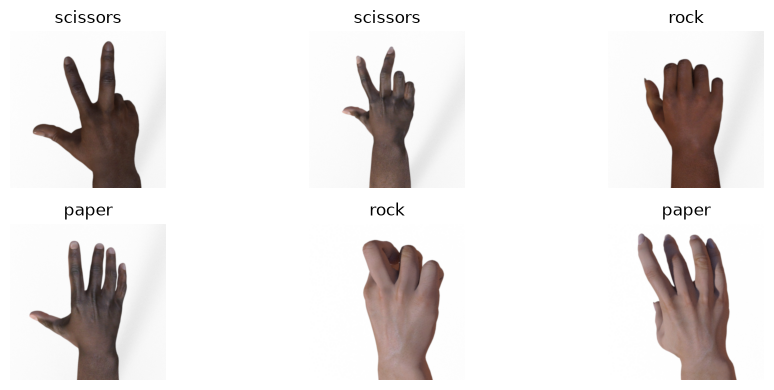

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))
for i, (image, label) in enumerate(train_ds_raw.take(6)):
    plt.subplot(2, 3, i + 1)
    plt.imshow(image.numpy())
    plt.title(class_names[label.numpy()])
    plt.axis("off")
plt.tight_layout()
plt.show()

In [10]:
IMG_SIZE = 128
BATCH_SIZE = 32

def preprocess(image, label):
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    image = image / 255.0
    return image, label

train_ds = (
    train_ds_raw
    .map(preprocess, num_parallel_calls=tf.data.AUTOTUNE)
    .shuffle(1000)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

test_ds = (
    test_ds_raw
    .map(preprocess, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
], name="data_augmentation")

In [11]:
from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
    data_augmentation,

    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(num_classes, activation="softmax"),
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,288,067 (16.36 MB)

 Trainable params: 4,288,067 (16.36 MB)

 Non-trainable params: 0 (0.00 B)

In [12]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=5, restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        "rps_cnn_best.keras", monitor="val_loss", save_best_only=True
    ),
]

history = model.fit(
    train_ds,
    validation_data=test_ds,
    epochs=30,
    callbacks=callbacks,
)

Epoch 1/30
79/79 ━━━━━━━━━━━━━━━━━━━━ 18s 207ms/step - accuracy: 0.5278 - loss: 0.9376 - val_accuracy: 0.7715 - val_loss: 0.6199
Epoch 2/30
79/79 ━━━━━━━━━━━━━━━━━━━━ 17s 220ms/step - accuracy: 0.8881 - loss: 0.3142 - val_accuracy: 0.9194 - val_loss: 0.2138
Epoch 3/30
79/79 ━━━━━━━━━━━━━━━━━━━━ 15s 191ms/step - accuracy: 0.9571 - loss: 0.1536 - val_accuracy: 0.8925 - val_loss: 0.2299
Epoch 4/30
79/79 ━━━━━━━━━━━━━━━━━━━━ 15s 185ms/step - accuracy: 0.9627 - loss: 0.1061 - val_accuracy: 0.9247 - val_loss: 0.1981
Epoch 5/30
79/79 ━━━━━━━━━━━━━━━━━━━━ 16s 204ms/step - accuracy: 0.9734 - loss: 0.0799 - val_accuracy: 0.9194 - val_loss: 0.3211
Epoch 6/30
79/79 ━━━━━━━━━━━━━━━━━━━━ 17s 209ms/step - accuracy: 0.9825 - loss: 0.0602 - val_accuracy: 0.9489 - val_loss: 0.2387
Epoch 7/30
79/79 ━━━━━━━━━━━━━━━━━━━━ 16s 207ms/step - accuracy: 0.9829 - loss: 0.0490 - val_accuracy: 0.9597 - val_loss: 0.1538
Epoch 8/30
79/79 ━━━━━━━━━━━━━━━━━━━━ 15s 191ms/step - accuracy: 0.9873 - loss: 0.0363 - val_accu

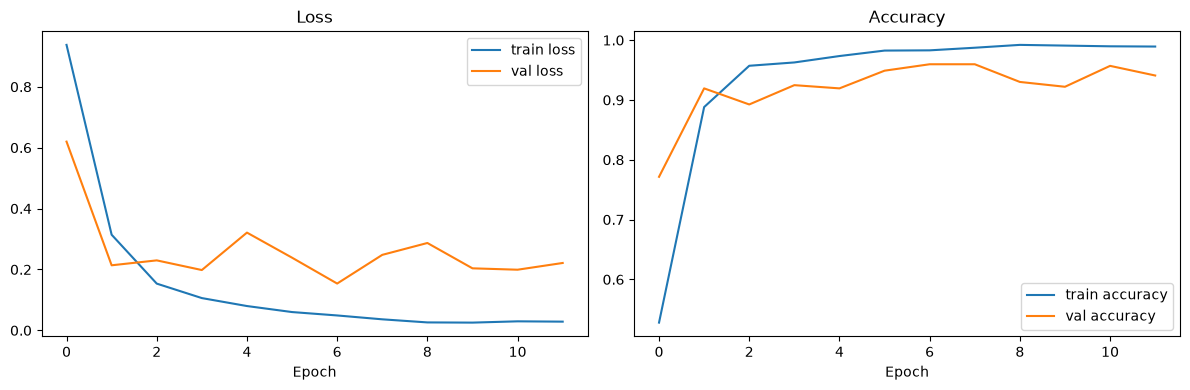

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history["loss"], label="train loss")
axes[0].plot(history.history["val_loss"], label="val loss")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(history.history["accuracy"], label="train accuracy")
axes[1].plot(history.history["val_accuracy"], label="val accuracy")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.show()

In [14]:
test_loss, test_accuracy = model.evaluate(test_ds)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")

12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - accuracy: 0.9597 - loss: 0.1538
Test loss: 0.1538
Test accuracy: 0.9597


12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 55ms/step
              precision    recall  f1-score   support

        rock       1.00      0.98      0.99       124
       paper       0.98      0.92      0.95       124
    scissors       0.90      0.98      0.94       124

    accuracy                           0.96       372
   macro avg       0.96      0.96      0.96       372
weighted avg       0.96      0.96      0.96       372



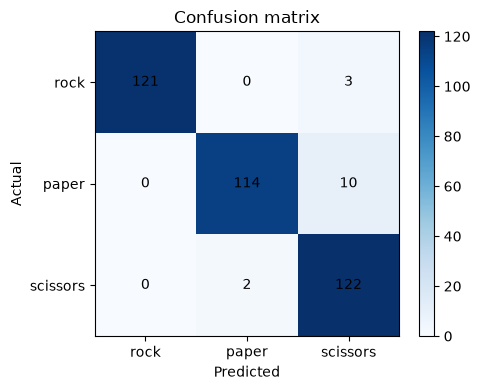

In [15]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report

y_true = np.concatenate([labels.numpy() for _, labels in test_ds], axis=0)
y_pred_probs = model.predict(test_ds)
y_pred = np.argmax(y_pred_probs, axis=1)

print(classification_report(y_true, y_pred, target_names=class_names))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(5, 4))
plt.imshow(cm, cmap="Blues")
plt.xticks(range(num_classes), class_names)
plt.yticks(range(num_classes), class_names)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion matrix")
for i in range(num_classes):
    for j in range(num_classes):
        plt.text(j, i, cm[i, j], ha="center", va="center")
plt.colorbar()
plt.tight_layout()
plt.show()

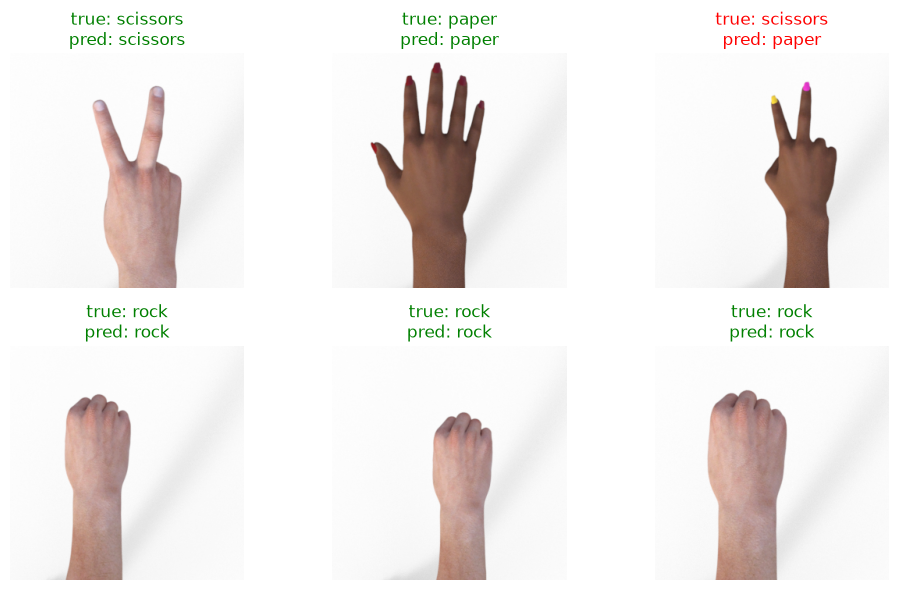

In [16]:
plt.figure(figsize=(10, 6))
for i, (image, label) in enumerate(test_ds_raw.take(6)):
    resized = tf.image.resize(image, (IMG_SIZE, IMG_SIZE)) / 255.0
    pred_probs = model.predict(tf.expand_dims(resized, axis=0), verbose=0)
    pred_label = class_names[np.argmax(pred_probs)]
    true_label = class_names[label.numpy()]

    plt.subplot(2, 3, i + 1)
    plt.imshow(image.numpy())
    color = "green" if pred_label == true_label else "red"
    plt.title(f"true: {true_label}\npred: {pred_label}", color=color)
    plt.axis("off")
plt.tight_layout()
plt.show()

In [17]:
model.save("rps_cnn_final.keras")
print("Model saved to rps_cnn_final.keras")

Model saved to rps_cnn_final.keras
